
# But du laboratoire

L'objectif est d'apprendre à utiliser les modules numpy et matplotlib, pour manipuler des tableaux et afficher des graphiques.

# Travail obligatoire


In [1]:

import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline
#%matplotlib qt

## Exercice 1 : "Dessin d'un cercle sur matplotlib"

Dans cet exercice, vous devez utiliser la fonction plot de matplotlib pour dessiner un cercle de rayon 1, ainsi qu'un hexagone inscrit dans le cercle.

1. Déclarer un vecteur $\theta_1$, contenant 1000 points répartis linéairement entre 0 et $2\pi$
2. Définir, `x1` et `y1` en fonction de $\theta_1$ :
   * $x1 = cos(\theta_1)$
   * $y1 = sin(\theta_1)$
3. Créer une figure `matplotlib`, et représenter graphiquement `y1` en fonction de `x1`.
4. Ajouter, sur le même graphique, un hexagone inscrit dans le cercle. Vous allez pour cela utiliser les mêmes fonctions que pour le cercle :
    * Déclarer un vecteur $\theta_2$, contenant cette fois-ci 7 points, répartis linéairement entre 0 et $2\pi$
    * Définir `x2` et `y2` en fonciton de $\theta_2$
    * Représenter graphiquement `y2` en fonction de `x2`. La courbe va contenir uniquement 7 points (dont 2 aux mêmes coordonnées), situés sur le cercle unité. Matplotlib va relier les points pour former un hexagone.
5. Mettez en forme le graphique avec :
    * Un titre
    * Des labels sur les axes
    * Un quadrillage
6. Assurez-vous que les axes du graphique soient orthogonaux. Vous pouvez pour cela utiliser `plt.axis('equal')`.


(np.float64(-1.1),
 np.float64(1.1),
 np.float64(-1.0999986402114572),
 np.float64(1.0999986402114572))

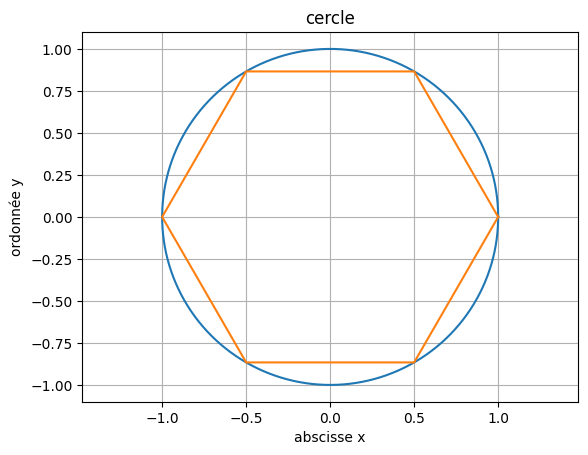

In [6]:
### Votre code

vecteur = np.linspace(0, 2*np.pi, 1000)  # 1000 points from 0 to 2pi

x = np.cos(vecteur)
y = np.sin(vecteur)

vecteur_2 = np.linspace(0, 2*np.pi, 7)  # 1000 points from 0 to 2pi

x2 = np.cos(vecteur_2)
y2 = np.sin(vecteur_2)

plt.plot(x,y)
plt.plot(x2,y2)
plt.title("cercle")
plt.xlabel("abscisse x")
plt.ylabel("ordonnée y")
plt.grid()   # enclencher la grille
plt.axis('equal')
###




## Exercice 2 : "Opérations sur des signaux"

L'objectif est de manipuler des signaux et d'explorer quelques opérations de base.

1. Créez un signal sinusoïdal `x1` d'amplitude 2, et contenant 1000 points entre 0 et $2\pi$
2. Obtenez le signal `x2` en prenant la valeur absolue du signal `x1`.
3. Copiez le signal `x1` pour obtenir un nouveau signal `x3`, et mettez à zéro toutes les valeurs pour lesquelles le signal est négatif.
4. Calculer la valeur efficace des 3 signaux de 2 manières différentes : en utilisant la somme des carrés (opérateur `**` et fonction `np.sum()`), et en utilisant le produit scalaire (`np.dot()` ou `@`). La valeur efficace d'un signal :
    
    $$X=\sqrt{\frac{1}{N}\displaystyle\sum\limits_{i=0}^{N-1} x(i)^2}$$

5. Trouvez le point (en x et y) où se trouve le maximum du signal `x1`, en utilisant la fonction `np.argmax()`.
6. A l'aide de `plt.subplot()`, afficher sur une même figure les signaux obtenus, avec titre, labels sur les axes et légende. Sur le plot du signal `x1`, affichez une croix sur le maximum. La taille de la figure peut être modifiée grâce à l'argument `figsize` de la fonction `plt.figure()`
7. Testez votre code en ajoutant soit `%matplotlib inline`, soit `%matplotlib qt` avant la création du graphique. Avec `qt`, vous pouvez zoomer sur le graphique. Trouvez quel argument de `plt.subplot()` vous devez utiliser pour partager l'axe des abcisses entre les subplots. De cette manière, un zoom sur l'un des subplots engendrera le même zoom sur les autres subplots.


In [ ]:

%matplotlib inline
#%matplotlib qt

### Votre code

vecteur = np.linspace(0, 2*np.pi, 1000)  # 1000 points from 0 to 2pi

x = 2*np.cos(vecteur)

x2 = np.absolute(x)

# Mettre à zéro toutes les valeurs négatives de x pour obtenir x3
x3 = x.copy()
if np.any(x3 < 0):
    x3[x3 < 0] = 0

#valeur efficace X1
x_eff = np.sqrt(np.sum(x**2)/len(x))
print(x_eff)

# Valeur efficace X2
x2_eff = np.sqrt(np.sum(x2**2)/len(x2))
print(x2_eff)

# Valeur efficace X3
x3_eff = np.sqrt(np.sum(x3**2)/len(x3))
print(x3_eff)

# Valeur efficace X1
produit_scalaire = np.dot(x, x)
x1_eff = np.sqrt(produit_scalaire / 1000)
print(x1_eff)

# Valeur efficace X2
produit_scalaire = np.dot(x2, x2)
x2_eff = np.sqrt(produit_scalaire / 1000)
print(x2_eff)

# Valeur efficace X2
produit_scalaire = np.dot(x3, x3)
x3_eff = np.sqrt(produit_scalaire / 1000)
print(x3_eff)

max_y = np.argmax(x1)

plt.plot(vecteur,x)
plt.plot(vecteur,x2)
plt.plot(vecteur,x3)
plt.plot(max_y, 'kx', markersize=10, label="Maximum de x")  # Cross at max

plt.title("cercle")
plt.xlabel("abscisse x")
plt.ylabel("ordonnée y")
plt.grid()   # enclencher la grille
plt.axis('equal')
###

NameError: name 'np' is not defined

## Exercice 3 : "Régression polynomiale"

Cet exercice a pour but de découvrir le module `polynomial` de numpy, ainsi que de réaliser des graphiques avec des barres d'erreur.

On vous fournit les listes `L` et `F` qui représentent la longueur d'un ressort et la force qui lui est appliquée, mesurée à l'aide d'un dynamomètre. L'incertitude sur la mesure de la force est de 0.5N, et est représenté par `F_UNCERTAINTY`.

1. Tracer le graphique de la force en fonction de la longueur, avec des barres d'erreurs. Utiliser la fonction `errorbar()` de matplotlib, avec les arguments `capsize` et `mew` pour obtenir la même mise en forme que sur l'exemple.
2. A l'aide du module `polynomial`, calculer et évaluer les régressions du 1er ordre et du 3ème ordre sur la série de mesure :
    * La fonction `polyfit()` permet de trouver les coefficients du modèle
    * `p = Polynomial(coefs)` permet de créer un polynome à partir des coefficients, qui pourra ensuite être évalué à différentes valeurs de `x`
    * Pour tracer la courbe, vous devrez d'abord créer un vecteur `x` allant de 0 à 20 en utilisant `np.linspace()`, puis vous pourrez évaluer votre polynome aux valeurs de `x` en exécutant `y = p(x)`.
3. Calculez l'erreur quadratique moyenne (MSE) pour les 2 types de régression, selon la formule suivante :
    $$MSE = \frac{1}{N} \sum_{i=0}^{N-1} (y_i-\hat{y}_i)^2$$
    * $N$ correspond au nombre d'échantillons mesurés, $y_i$ à la mesure, et $\hat{y}_i$ à la valeur estimée par le modèle
    * Pour calculer la MSE, vous devrez évaluer les 2 types de régression, pour les longueurs correspondant à la mesure. C'est ces valeurs qui vont correspondre à $\hat{y}_i$

In [4]:
L = [4.2,5.0,6.0,7.0,8.0,9.0,10.0,11.0,12.0,13.0,14.0]  # Longueur en cm
F = [0.0,1.1,2.0,3.2,3.9,4.6,5.8,7.0,8.3,9.0,9.5]       # Force en newton
F_UNCERTAINTY = 0.5     # Incertitue sur la force [N]

from numpy.polynomial.polynomial import polyfit
from numpy.polynomial import Polynomial

### Votre code


###

## Exercice 4 : "Détecteur piece"
Le but de cet exercice est de se familiariser avec les images et les matrices en 2D.
Pour ce faire, une image d'une pièce est bruitée et pas centrée. L'objectif est de couper l'image afin de ne garder que la pièce.

1. Lire l'image avec `img = plt.imread('data/coins.bmp')` et afficher l'image avec `plt.imshow()`.
2. Afficher les informations suivante de la matrice `img` :
   - dimensions : `np.shape(img)` 
   - valeur minimum : `np.min()` 
   - valeur maximum : `np.max()`
   - type de la matrice: `type()`
   - type d'une valeur (pixel) : `type(img[0,0])`
3. Binariser l'image. Celà consiste à tester si les pixels sont plus grand qu'un seuil `T` : `img > T`
4. Sommer indépendemment chaque axe de la matrice. Celà correspond à une projection horizontale ou verticale `proj = np.sum(img,axis = ...)`
5. Afficher chaque projection et déterminer le début et la fin de la pièce en utilisant pour chaque projection `np.where(proj > ...)`
6. Couper l'image en utilisant les débuts et fins obtenus.

In [5]:


### Votre code


###
